In [3]:
##1. 导入库

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import ExtraTreesRegressor

In [4]:
##2. 读取数据
data = pd.read_csv(
    "E:/project/1/data/processed/PJME_feature_engineered.csv"
)

print(data.head())
print(data.shape)
print(data.columns)

              Datetime  PJME_MW  hour  dayofweek  month  quarter  year  \
0  2002-01-08 01:00:00  29445.0     1          1      1        1  2002   
1  2002-01-08 02:00:00  28670.0     2          1      1        1  2002   
2  2002-01-08 03:00:00  28375.0     3          1      1        1  2002   
3  2002-01-08 04:00:00  28542.0     4          1      1        1  2002   
4  2002-01-08 05:00:00  29261.0     5          1      1        1  2002   

   dayofyear  is_weekend    lag_1   lag_24  lag_168  rolling_mean_24  \
0          8           0  31187.0  26862.0  30393.0     33452.583333   
1          8           0  29445.0  25976.0  29265.0     33560.208333   
2          8           0  28670.0  25641.0  28357.0     33672.458333   
3          8           0  28375.0  25666.0  27899.0     33786.375000   
4          8           0  28542.0  26328.0  28057.0     33906.208333   

   rolling_mean_168  
0      32519.511905  
1      32513.869048  
2      32510.327381  
3      32510.434524  
4      32514

In [5]:
##3. 选择特征与标签

feature_cols = [
    "hour",
    "dayofweek",
    "month",
    "quarter",
    "year",
    "is_weekend",
    "lag_1",
    "lag_24",
    "lag_168",
    "rolling_mean_24",
    "rolling_mean_168"
]

target_col = "PJME_MW"

X = data[feature_cols]
y = data[target_col]

print(X.shape)
print(y.shape)

(145198, 11)
(145198,)


In [6]:
##4.划分训练集、验证集、测试集

train_end = int(len(data) * 0.7)
val_end = int(len(data) * 0.85)

x_train = X.iloc[:train_end]
x_val = X.iloc[train_end:val_end]
x_test = X.iloc[val_end:]

y_train = y.iloc[:train_end]
y_val = y.iloc[train_end:val_end]
y_test = y.iloc[val_end:]

print("x_train:", x_train.shape)
print("x_val:", x_val.shape)
print("x_test:", x_test.shape)

print("y_train:", y_train.shape)
print("y_val:", y_val.shape)
print("y_test:", y_test.shape)



x_train: (101638, 11)
x_val: (21780, 11)
x_test: (21780, 11)
y_train: (101638,)
y_val: (21780,)
y_test: (21780,)


In [5]:
##5.定义评价函数
def evaluate_model(y_true, y_pred, model_name, dataset_name):
    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_true, y_pred)
    )

    mape = np.mean(
        np.abs((y_true - y_pred) / y_true)
    ) * 100

    r2 = r2_score(y_true, y_pred)

    result = {
        "Model": model_name,
        "Dataset": dataset_name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE": mape,
        "R2": r2
    }

    return result

In [6]:
##6. 建立模型字典

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42
    ),

     "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

     "Gradient Boosting": GradientBoostingRegressor(
        random_state=42
    ),

     "Extra Trees": ExtraTreesRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
    
}

In [7]:
##7. 循环训练和评价

all_results = []
predictions = {}

for model_name,model in models.items():
    print("Training:", model_name)

    model.fit(
        x_train,
        y_train
    )

    y_val_pred = model.predict(
        x_val
    )

    y_test_pred = model.predict(
        x_test
    )

    val_result = evaluate_model(
        y_val,
        y_val_pred,
        model_name,
        "Validation"
    )

    test_result = evaluate_model(
        y_test,
        y_test_pred,
        model_name,
        "Test"
    )

    all_results.append(val_result)
    all_results.append(test_result)

    predictions[model_name] = {
        "Validation": y_val_pred,
        "Test": y_test_pred
    }


Training: Linear Regression
Training: Decision Tree
Training: Random Forest
Training: Gradient Boosting
Training: Extra Trees


In [8]:
##9.生成结果表

result_df = pd.DataFrame(all_results)

result_df


,Model,Dataset,MAE,RMSE,MAPE,R2
0,Linear Regression,Validation,967.721276,1242.027053,3.092213,0.959647
1,Linear Regression,Test,967.969320,1236.222944,3.123885,0.963186
2,Decision Tree,Validation,426.479706,629.618169,1.323771,0.989630
3,Decision Tree,Test,458.016667,652.071667,1.459999,0.989757
4,Random Forest,Validation,315.643612,449.796866,0.978255,0.994708
5,Random Forest,Test,344.620787,473.358234,1.098064,0.994602
6,Gradient Boosting,Validation,562.181239,732.993688,1.761839,0.985945
7,Gradient Boosting,Test,569.152087,733.922807,1.823487,0.987024
8,Extra Trees,Validation,302.239876,418.372810,0.943023,0.995421
9,Extra Trees,Test,341.446694,461.729579,1.095325,0.994864


In [9]:
## 单独查看测试结果

test_result_df = result_df[
    result_df["Dataset"] == "Test"
].copy()

## 从result_df 这个总结果表中，筛选出 Dataset 等于 "Test" 的行，并复制成一个新的表 test_result_df。

test_result_df = test_result_df.sort_values(
    "RMSE",
    ascending=True
)

test_result_df

,Model,Dataset,MAE,RMSE,MAPE,R2
9,Extra Trees,Test,341.446694,461.729579,1.095325,0.994864
5,Random Forest,Test,344.620787,473.358234,1.098064,0.994602
3,Decision Tree,Test,458.016667,652.071667,1.459999,0.989757
7,Gradient Boosting,Test,569.152087,733.922807,1.823487,0.987024
1,Linear Regression,Test,967.969320,1236.222944,3.123885,0.963186


In [10]:
## 保存结果

result_df.to_csv(
    "E:/project/1/results/metrics/03_all_model_comparison.csv",
    index=False
)

test_result_df.to_csv(
    "E:/project/1/results/metrics/03_test_model_comparison.csv",
    index=False
)

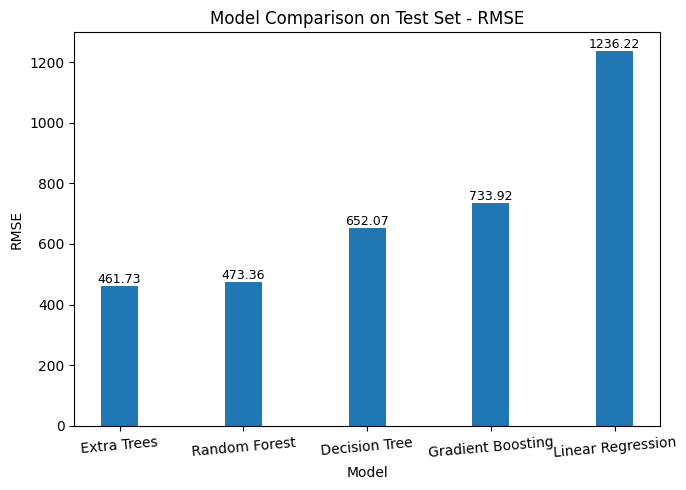

In [11]:
##10.模型指标对比图
## RMSE 对比
plt.figure(figsize=(7, 5))

bars = plt.bar(
    test_result_df["Model"],## 横轴：模型名称
    test_result_df["RMSE"], ## 纵轴：RMSE
    width =0.3
)

plt.title("Model Comparison on Test Set - RMSE")
plt.xlabel("Model")
plt.ylabel("RMSE")
plt.xticks(rotation=5)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.savefig(
    "E:/project/1/results/figures/03_model_comparison_rmse.png",
    dpi=300
)
plt.show()

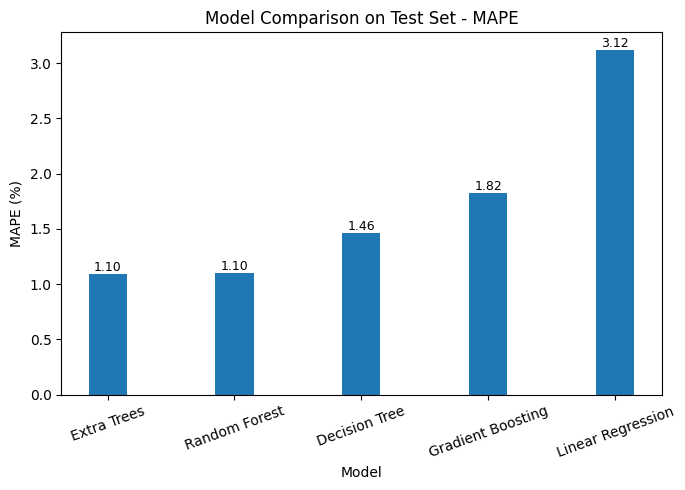

In [15]:
## MAPE 对比

plt.figure(figsize=(7, 5))

bars = plt.bar(
    test_result_df["Model"],
    test_result_df["MAPE"],
    width = 0.3
)

plt.title("Model Comparison on Test Set - MAPE")
plt.xlabel("Model")
plt.ylabel("MAPE (%)")
plt.xticks(rotation=20)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.savefig(
    "E:/project/1/results/figures/03_model_comparison_mape.png",
    dpi=300
)
plt.show()

In [17]:
top3_models = test_result_df["Model"].head(3).tolist()
## .tolist() 将Pandas数据转化为 python 列表
top3_models

['Extra Trees', 'Random Forest', 'Decision Tree']

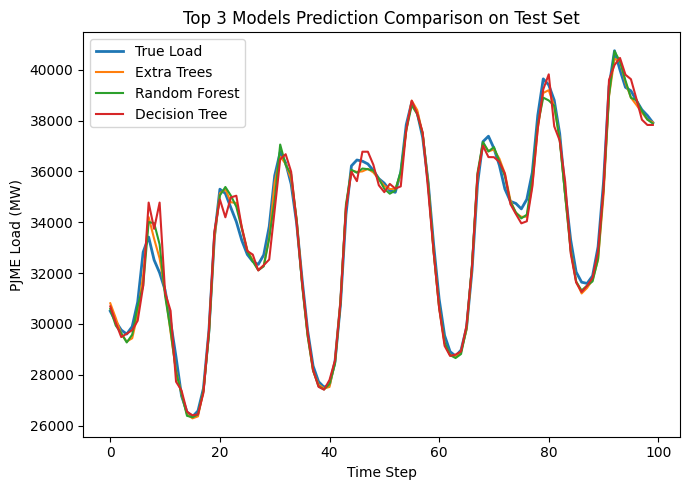

In [22]:
## Top3模型预测曲线

plt.figure(figsize=(7, 5))

plt.plot(
    y_test.values[:100],
    label="True Load",
    linewidth=2
)

for model_name in top3_models:
    plt.plot(
        predictions[model_name]["Test"][:100],
        label=model_name
    )

plt.title("Top 3 Models Prediction Comparison on Test Set")
plt.xlabel("Time Step")
plt.ylabel("PJME Load (MW)")
plt.legend()
plt.tight_layout()
plt.savefig(
    "E:/project/1/results/figures/03_top3_prediction_comparison.png",
    dpi=300
)
plt.show()

In [19]:
best_model_name = test_result_df.iloc[0]["Model"]
best_rmse = test_result_df.iloc[0]["RMSE"]
best_mape = test_result_df.iloc[0]["MAPE"]
best_r2 = test_result_df.iloc[0]["R2"]

print("Best Model:", best_model_name)
print("Best RMSE:", best_rmse)
print("Best MAPE:", best_mape)
print("Best R2:", best_r2)

Best Model: Extra Trees
Best RMSE: 461.7295786569967
Best MAPE: 1.0953252304102552
Best R2: 0.9948642995966083


In [ ]:
## 模型对比结论

在相同特征工程和相同数据划分条件下，本文对 Linear Regression、Decision Tree、Random Forest、Gradient Boosting 和 Extra Trees 等模型进行了对比实验。
实验结果表明，不同模型在 PJME 电力负荷预测任务上的表现存在明显差异。

从测试集结果来看，RMSE 最低的模型为 Extra Trees，说明该模型在整体预测误差方面表现最好。
相比 Linear Regression，集成树模型能够更好地刻画电力负荷数据中的非线性关系和周期性波动特征。
从预测曲线可以看出，Extra Trees 模型对真实负荷曲线的跟随能力更强，在大多数时间段能够较好拟合负荷变化趋势。

总体而言，在当前特征工程条件下，Extra Trees 模型更适合作为后续深度学习模型对比前的传统机器学习最优基线。

In [1]:
## 2026-11-23 决策树原理学习

from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [10]:
## 创建不同深度的决策树

depths = [1, 2, 3, 5, 8, 12, 16, 20, 24, 28, 32, None]

results = []

for depth in depths:

    # 创建决策树
    model = DecisionTreeRegressor(
        max_depth=depth,
        random_state=42
    )

    # 模型训练
    model.fit(x_train, y_train)

    # 训练集预测
    y_train_pred = model.predict(x_train)

    # 验证集预测
    y_val_pred = model.predict(x_val)
    
    # 计算训练集 RMSE
    train_rmse = np.sqrt(
        mean_squared_error(y_train, y_train_pred)
    )

    # 计算验证集 RMSE
    val_rmse = np.sqrt(
        mean_squared_error(y_val, y_val_pred)
    )

    # 计算验证集 MAE
    val_mae = mean_absolute_error(y_val, y_val_pred)

    # 计算验证集 R²
    val_r2 = r2_score(y_val, y_val_pred)

    results.append({
        "max_depth": depth,
        "Train_RMSE": train_rmse,
        "Val_RMSE": val_rmse,
        "Val_MAE": val_mae,
        "Val_R2": val_r2
    })

# 输出实验结果
tree_result_df = pd.DataFrame(results)

display(tree_result_df)

,max_depth,Train_RMSE,Val_RMSE,Val_MAE,Val_R2
0,1.0,4219.342323,3898.175557,3147.951561,0.602499
1,2.0,2568.568588,2476.379868,2024.327648,0.839583
2,3.0,1847.208340,1750.858624,1408.987449,0.919810
3,5.0,1283.469896,1261.565222,1008.972135,0.958367
4,8.0,805.182179,861.108123,642.621182,0.980603
5,12.0,536.890699,646.215412,451.870716,0.989076
6,16.0,290.199533,595.073134,403.335172,0.990737
7,20.0,122.403979,624.031536,421.432027,0.989813
8,24.0,39.021940,631.660314,427.803820,0.989563
9,28.0,10.073539,629.762080,427.529763,0.989625


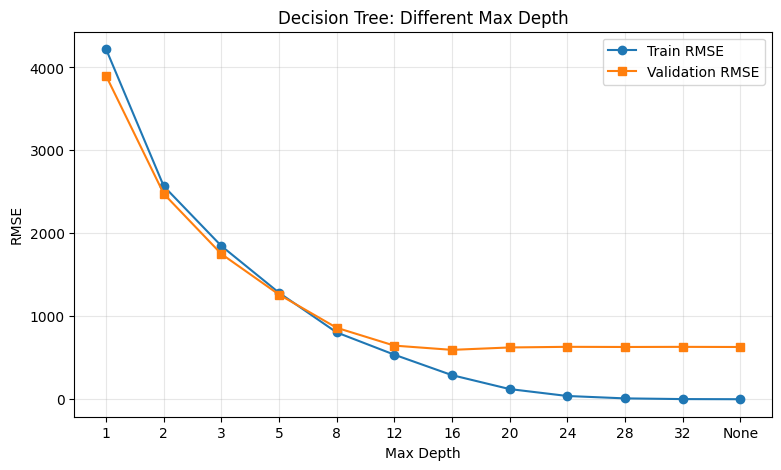

In [11]:
plt.figure(figsize=(9, 5))

depth_labels = [
    "None" if d is None else str(d)
    for d in depths
]

plt.plot(
    depth_labels,
    tree_result_df["Train_RMSE"],
    marker="o",
    label="Train RMSE"
)

plt.plot(
    depth_labels,
    tree_result_df["Val_RMSE"],
    marker="s",
    label="Validation RMSE"
)

plt.xlabel("Max Depth")
plt.ylabel("RMSE")

plt.title("Decision Tree: Different Max Depth")

plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [ ]:
## 实验结论

本实验通过调整决策树回归模型的最大深度参数 max_depth，研究模型复杂度对电力负荷预测效果的影响。
实验分别设置 max_depth 为 1、2、3、5、8、12、16、20、24、28、32 和 None，
并通过训练集 RMSE、验证集 RMSE、MAE 和 R² 等指标对模型性能进行评估。

实验结果表明，随着 max_depth 从 1 增加到 16，训练集 RMSE 和验证集 RMSE 均呈现下降趋势，
说明适当增加决策树深度能够提高模型对数据特征的学习能力，改善模型的拟合效果。
当 max_depth=16 时，模型取得了当前实验中最好的验证集表现，验证集 RMSE 为 595.07，MAE 为 403.34，R² 为 0.990737。

当 max_depth 继续增加到 20、24、28、32 以及 None 时，训练集 RMSE 继续下降，甚至在 max_depth=None 时降至 0，但验证集 RMSE 不再下降，反而有所上升。
这表明模型随着深度增加变得越来越复杂，开始过度拟合训练数据，导致泛化能力下降。

综上所述，决策树的最大深度并非越大越好，需要在模型拟合能力和泛化能力之间取得平衡。在本次实验测试的参数范围内，max_depth=16 时模型的综合预测表现最好，
因此选择 max_depth=16 作为当前决策树模型的最优参数。
